# Mahurangi LSTM — High-Water-Risk Classification

This notebook develops an **Mahurangi-specific LSTM** using the same high-water-risk definition and chronological train/validation/test periods used in the original Otara classification workflow.

### Objective
Use the recent sequence of:

- `rainfall_mm`
- `discharge_m3s`
- `water_level_m`

to estimate whether the water level will exceed the **Mahurangi high-water-risk threshold during the next 24 hours**.

### Main methodological decisions
- The data remain in chronological order.
- The split is approximately 70% train, 15% validation, and 15% test.
- The high-water-risk threshold is calculated **using training data only**.
- The test set is not used for training, threshold selection, or hyperparameter tuning.
- Missing input values are not interpolated: a sequence is used only if all hours contain all three input variables.
- A **48-hour lookback** is used, matching the Mahurangi LSTM pipeline.
- Class imbalance is handled with `pos_weight`.
- The final probability threshold is selected on validation data using the **F2-score**, which gives more weight to recall.

## Pipeline Design

`mahurangi_cleaned_hourly.csv` → temporal audit → chronological split → 24-hour target → scaling fitted on train → 48-hour sequences → class weighting → LSTM → probability threshold selected on validation → final test → episode-level evaluation.

The test set is not used for training or probability-threshold selection.

In [1]:
%pip install torch scikit-learn joblib
%pip install --upgrade typing_extensions

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [2]:
import sys
import torch

print("Python:", sys.executable)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

x = torch.rand(5, 3)
print(x)

Python: C:\Users\lauso\anaconda3\python.exe
PyTorch: 2.14.1+cpu
CUDA available: False
tensor([[0.6947, 0.2605, 0.6992],
        [0.2538, 0.7030, 0.6193],
        [0.0280, 0.9769, 0.9842],
        [0.4995, 0.1187, 0.6227],
        [0.1318, 0.1713, 0.4778]])


## Libraries

In [3]:
import os
import copy
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    accuracy_score,
    roc_auc_score,
    average_precision_score,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay,
)

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

PyTorch: 2.14.1+cpu
CUDA available: False


## 2. Load the Clean Hourly Time Series

In [4]:
candidate_paths = [
    Path("mahurangi_cleaned_hourly.csv"),
    Path("/mnt/data/mahurangi_cleaned_hourly.csv"),
]

data_path = next((p for p in candidate_paths if p.exists()), None)

if data_path is None:
    raise FileNotFoundError(
        "mahurangi_cleaned_hourly.csv was not found. "
        "Pon el CSV en la misma carpeta del notebook."
    )

df = pd.read_csv(data_path)
df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce")

df = (
    df[
        ["timestamp", "rainfall_mm", "discharge_m3s", "water_level_m"]
    ]
    .sort_values("timestamp")
    .reset_index(drop=True)
)

print("Loaded:", data_path)
display(df.head())

Loaded: mahurangi_cleaned_hourly.csv


,timestamp,rainfall_mm,discharge_m3s,water_level_m
0,2015-01-01 01:00:00,0.00,0.323,1.332
1,2015-01-01 02:00:00,0.00,0.423,1.349
2,2015-01-01 03:00:00,1.25,0.461,1.355
3,2015-01-01 04:00:00,1.24,0.410,1.347
4,2015-01-01 05:00:00,0.00,0.374,1.341


## 3. Audit the Temporal Structure

In [5]:
print("Shape:", df.shape)
print("Date range:", df["timestamp"].min(), "to", df["timestamp"].max())
print("Duplicate timestamps:", df["timestamp"].duplicated().sum())
print("\nMissing values:")
print(df.isna().sum())

time_difference = df["timestamp"].diff()
non_hourly_gap = (
    time_difference.notna()
    & (time_difference != pd.Timedelta(hours=1))
)
print("\nNon-hourly gaps:", non_hourly_gap.sum())

Shape: (96432, 4)
Date range: 2015-01-01 01:00:00 to 2026-01-01 00:00:00
Duplicate timestamps: 0

Missing values:
timestamp         0
rainfall_mm       0
discharge_m3s    90
water_level_m    88
dtype: int64

Non-hourly gaps: 0


## 4. Chronological Split

The original split is reproduced: approximately 70% train, 15% validation, and 15% test.

In [6]:
model_data = df.copy()
number_of_rows = len(model_data)

train_end = int(number_of_rows * 0.70)
validation_end = int(number_of_rows * 0.85)

model_data["data_period"] = "test"
model_data.loc[model_data.index < train_end, "data_period"] = "train"
model_data.loc[
    (model_data.index >= train_end)
    & (model_data.index < validation_end),
    "data_period"
] = "validation"

split_summary = (
    model_data.groupby("data_period")
    .agg(
        rows=("timestamp", "size"),
        beginning=("timestamp", "min"),
        ending=("timestamp", "max"),
    )
    .loc[["train", "validation", "test"]]
)

display(split_summary)

,rows,beginning,ending
data_period,,,
train,67502,2015-01-01 01:00:00,2022-09-13 14:00:00
validation,14465,2022-09-13 15:00:00,2024-05-08 07:00:00
test,14465,2024-05-08 08:00:00,2026-01-01 00:00:00


## 5. Reproduce the Threshold and Next-24-Hour Target

In [7]:
HIGH_WATER_PERCENTILE = 0.995

high_water_threshold = (
    model_data.loc[
        model_data["data_period"] == "train",
        "water_level_m"
    ]
    .quantile(HIGH_WATER_PERCENTILE)
)

print("Training-only high-water threshold:", round(high_water_threshold, 3), "m")

Training-only high-water threshold: 2.43 m


In [8]:
FORECAST_HORIZON = 24

future_water_levels = pd.concat(
    [
        model_data["water_level_m"].shift(-hour)
        for hour in range(1, FORECAST_HORIZON + 1)
    ],
    axis=1
)

future_water_levels.columns = [
    f"water_level_t_plus_{hour}"
    for hour in range(1, FORECAST_HORIZON + 1)
]

model_data["future_24h_max_water_level"] = (
    future_water_levels.max(axis=1, skipna=False)
)

model_data["flood_next_24h"] = np.where(
    model_data["future_24h_max_water_level"].isna(),
    np.nan,
    (
        model_data["future_24h_max_water_level"]
        >= high_water_threshold
    ).astype(int)
)

# Evitar que el target de 24h cruce entre train, validation y test.
future_periods = pd.concat(
    [
        model_data["data_period"].shift(-hour)
        for hour in range(1, FORECAST_HORIZON + 1)
    ],
    axis=1
)

same_period_target = future_periods.eq(
    model_data["data_period"],
    axis=0
).all(axis=1)

model_data.loc[
    ~same_period_target,
    ["future_24h_max_water_level", "flood_next_24h"]
] = np.nan

print(
    "Unavailable or boundary-crossing targets:",
    model_data["flood_next_24h"].isna().sum()
)

Unavailable or boundary-crossing targets: 1051


In [9]:
target_summary = (
    model_data.dropna(subset=["flood_next_24h"])
    .groupby("data_period")["flood_next_24h"]
    .agg(
        total_rows="count",
        flood_hours="sum",
        flood_percentage="mean",
    )
    .loc[["train", "validation", "test"]]
)

target_summary["flood_percentage"] *= 100
display(target_summary.round(3))

,total_rows,flood_hours,flood_percentage
data_period,,,
train,67276,1299.0,1.931
validation,14217,788.0,5.543
test,13888,402.0,2.895


## 6. Missing data

Rows are not removed from the full time series and missing values are not interpolated. An LSTM sequence is accepted only when **every hour** contains rainfall, discharge, and water level.

In [10]:
feature_columns = ["rainfall_mm", "discharge_m3s", "water_level_m"]

model_data["features_available"] = (
    model_data[feature_columns].notna().all(axis=1)
)

missing_rows = ~model_data["features_available"]

missing_groups = (
    missing_rows.ne(missing_rows.shift(fill_value=False)).cumsum()
)

missing_episodes = (
    model_data.loc[missing_rows]
    .assign(missing_group=missing_groups[missing_rows])
    .groupby("missing_group")
    .agg(
        start=("timestamp", "min"),
        end=("timestamp", "max"),
        hours=("timestamp", "size"),
    )
    .reset_index(drop=True)
)

print("Rows with missing features:", missing_rows.sum())
print("Missing-data episodes:", len(missing_episodes))
print("Longest episode:", missing_episodes["hours"].max(), "hours")
display(missing_episodes.head(10))

Rows with missing features: 90
Missing-data episodes: 41
Longest episode: 15 hours


,start,end,hours
0,2018-05-20 06:00:00,2018-05-20 10:00:00,5
1,2020-01-15 08:00:00,2020-01-15 09:00:00,2
2,2021-01-11 09:00:00,2021-01-11 09:00:00,1
3,2021-01-21 11:00:00,2021-01-21 11:00:00,1
4,2021-04-06 13:00:00,2021-04-06 13:00:00,1
5,2022-02-02 09:00:00,2022-02-02 11:00:00,3
6,2022-05-02 09:00:00,2022-05-02 14:00:00,6
7,2022-05-03 09:00:00,2022-05-03 12:00:00,4
8,2022-11-16 11:00:00,2022-11-16 11:00:00,1
9,2022-12-28 18:00:00,2022-12-28 18:00:00,1


## 7. Lookback

The model uses **48 hours** of historical data. Each sample has shape `(48, 3)`.

The notebook also reports how many samples would remain available with 24-, 48-, and 72-hour windows to document the effect of lookback length on sample availability.

In [11]:
LOOKBACK_HOURS = 48

lookback_rows = []

for lookback in [24, 48, 72]:
    valid_window = (
        model_data["features_available"].astype(int)
        .rolling(window=lookback, min_periods=lookback)
        .sum()
        .eq(lookback)
    )

    valid_sample = (
        valid_window
        & model_data["flood_next_24h"].notna()
    )

    for period_name in ["train", "validation", "test"]:
        lookback_rows.append({
            "lookback_hours": lookback,
            "data_period": period_name,
            "valid_samples": int(
                (
                    valid_sample
                    & model_data["data_period"].eq(period_name)
                ).sum()
            ),
        })

lookback_sample_counts = pd.DataFrame(lookback_rows)

display(
    lookback_sample_counts.pivot(
        index="lookback_hours",
        columns="data_period",
        values="valid_samples"
    )
)

data_period,test,train,validation
lookback_hours,,,
24,13384,67085,14003
48,12881,66893,13811
72,12378,66701,13619


## 8. Scaling Without Data Leakage

The `StandardScaler` is fitted only on complete rows from the **training set**. The same parameters are then applied to validation and test.

In [12]:
scaler_fit_mask = (
    model_data["data_period"].eq("train")
    & model_data["features_available"]
)

scaler = StandardScaler()
scaler.fit(model_data.loc[scaler_fit_mask, feature_columns])

scaled_features = scaler.transform(
    model_data[feature_columns]
).astype(np.float32)

display(
    pd.DataFrame({
        "train_mean": scaler.mean_,
        "train_scale": scaler.scale_,
    }, index=feature_columns)
)

,train_mean,train_scale
rainfall_mm,0.166841,0.897264
discharge_m3s,1.143804,3.744704
water_level_m,1.386209,0.183692


## 9. Convert the Time Series into 3D Sequences

In [13]:
from numpy.lib.stride_tricks import sliding_window_view

def create_sequences(data, scaled_array, lookback, period_name):
    targets = data["flood_next_24h"].to_numpy()
    periods = data["data_period"].to_numpy()

    row_available = np.isfinite(scaled_array).all(axis=1)

    complete_window = (
        pd.Series(row_available.astype(int))
        .rolling(window=lookback, min_periods=lookback)
        .sum()
        .to_numpy()
        == lookback
    )

    valid_end = (
        complete_window
        & np.isfinite(targets)
        & (periods == period_name)
    )

    end_indices = np.where(valid_end)[0]

    all_windows = (
        sliding_window_view(
            scaled_array,
            window_shape=lookback,
            axis=0
        )
        .transpose(0, 2, 1)
    )

    window_positions = end_indices - (lookback - 1)

    X = all_windows[window_positions].copy().astype(np.float32)
    y = targets[end_indices].astype(np.float32)
    timestamps = data.loc[end_indices, "timestamp"].to_numpy()

    return X, y, timestamps, end_indices


X_train, y_train, train_timestamps, train_indices = create_sequences(
    model_data, scaled_features, LOOKBACK_HOURS, "train"
)

X_validation, y_validation, validation_timestamps, validation_indices = create_sequences(
    model_data, scaled_features, LOOKBACK_HOURS, "validation"
)

print("X_train:", X_train.shape)
print("X_validation:", X_validation.shape)
print("Train positive %:", round(y_train.mean() * 100, 3))
print("Validation positive %:", round(y_validation.mean() * 100, 3))

X_train: (66893, 48, 3)
X_validation: (13811, 48, 3)
Train positive %: 1.942
Validation positive %: 5.467


## 10. Class imbalance



In [14]:
negative_count = int((y_train == 0).sum())
positive_count = int((y_train == 1).sum())

positive_weight = negative_count / positive_count

print("Negative samples:", negative_count)
print("Positive samples:", positive_count)
print("Positive class weight:", round(positive_weight, 3))

Negative samples: 65594
Positive samples: 1299
Positive class weight: 50.496


## 11. LSTM Architechture

In [15]:
class LSTMClassifier(nn.Module):
    def __init__(
        self,
        input_size=3,
        hidden_size=32,
        dense_size=16,
        dropout=0.25,
    ):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            batch_first=True,
        )
        self.dropout = nn.Dropout(dropout)
        self.dense = nn.Linear(hidden_size, dense_size)
        self.relu = nn.ReLU()
        self.output = nn.Linear(dense_size, 1)

    def forward(self, x):
        _, (hidden_state, _) = self.lstm(x)
        x = hidden_state[-1]
        x = self.dropout(x)
        x = self.relu(self.dense(x))
        return self.output(x).squeeze(1)


model = LSTMClassifier(
    input_size=len(feature_columns),
    hidden_size=32,
    dense_size=16,
    dropout=0.25,
)

print(model)
print(
    "Trainable parameters:",
    sum(p.numel() for p in model.parameters() if p.requires_grad)
)

LSTMClassifier(
  (lstm): LSTM(3, 32, batch_first=True)
  (dropout): Dropout(p=0.25, inplace=False)
  (dense): Linear(in_features=32, out_features=16, bias=True)
  (relu): ReLU()
  (output): Linear(in_features=16, out_features=1, bias=True)
)
Trainable parameters: 5281


## 12. Entrenamiento

- Adam optimizer, learning rate 0.001
- Batch size 512
- Maximum 15 epochs
- Early stopping based on validation PR-AUC
- Patience of 4 epochs
- The best model state is restored before evaluation

In [16]:
torch.manual_seed(SEED)
np.random.seed(SEED)

BATCH_SIZE = 512
MAX_EPOCHS = 15
PATIENCE = 4
LEARNING_RATE = 0.001
MIN_DELTA = 1e-4

model = LSTMClassifier(
    input_size=len(feature_columns),
    hidden_size=32,
    dense_size=16,
    dropout=0.25,
)

optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

loss_function = nn.BCEWithLogitsLoss(
    pos_weight=torch.tensor(positive_weight, dtype=torch.float32)
)

train_loader = DataLoader(
    TensorDataset(torch.from_numpy(X_train), torch.from_numpy(y_train)),
    batch_size=BATCH_SIZE,
    shuffle=False,
)

validation_loader = DataLoader(
    TensorDataset(
        torch.from_numpy(X_validation),
        torch.from_numpy(y_validation)
    ),
    batch_size=1024,
    shuffle=False,
)

best_validation_pr_auc = -np.inf
best_state = None
best_epoch = None
epochs_without_improvement = 0
training_history = []

for epoch in range(1, MAX_EPOCHS + 1):
    model.train()
    total_loss = 0.0

    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()
        logits = model(X_batch)
        loss = loss_function(logits, y_batch)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(y_batch)

    epoch_loss = total_loss / len(y_train)

    model.eval()
    validation_probability_parts = []

    with torch.no_grad():
        for X_batch, _ in validation_loader:
            probabilities = torch.sigmoid(model(X_batch))
            validation_probability_parts.append(
                probabilities.cpu().numpy()
            )

    validation_probabilities = np.concatenate(
        validation_probability_parts
    )

    validation_pr_auc = average_precision_score(
        y_validation, validation_probabilities
    )
    validation_roc_auc = roc_auc_score(
        y_validation, validation_probabilities
    )

    training_history.append({
        "epoch": epoch,
        "train_loss": epoch_loss,
        "validation_pr_auc": validation_pr_auc,
        "validation_roc_auc": validation_roc_auc,
    })

    print(
        f"Epoch {epoch:02d} | "
        f"loss={epoch_loss:.4f} | "
        f"val_PR_AUC={validation_pr_auc:.4f} | "
        f"val_ROC_AUC={validation_roc_auc:.4f}"
    )

    if validation_pr_auc > best_validation_pr_auc + MIN_DELTA:
        best_validation_pr_auc = validation_pr_auc
        best_state = copy.deepcopy(model.state_dict())
        best_epoch = epoch
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1
        if epochs_without_improvement >= PATIENCE:
            print("\nEarly stopping triggered.")
            break

model.load_state_dict(best_state)

history_df = pd.DataFrame(training_history)

print("\nBest epoch:", best_epoch)
print("Best validation PR-AUC:", round(best_validation_pr_auc, 4))
display(history_df)

Epoch 01 | loss=1.2242 | val_PR_AUC=0.4257 | val_ROC_AUC=0.8237
Epoch 02 | loss=1.0130 | val_PR_AUC=0.4537 | val_ROC_AUC=0.8278
Epoch 03 | loss=0.9302 | val_PR_AUC=0.4691 | val_ROC_AUC=0.8345
Epoch 04 | loss=0.8994 | val_PR_AUC=0.4780 | val_ROC_AUC=0.8369
Epoch 05 | loss=0.8898 | val_PR_AUC=0.4825 | val_ROC_AUC=0.8382
Epoch 06 | loss=0.8486 | val_PR_AUC=0.4864 | val_ROC_AUC=0.8411
Epoch 07 | loss=0.8643 | val_PR_AUC=0.4889 | val_ROC_AUC=0.8431
Epoch 08 | loss=0.8759 | val_PR_AUC=0.4892 | val_ROC_AUC=0.8431
Epoch 09 | loss=0.8664 | val_PR_AUC=0.4890 | val_ROC_AUC=0.8437
Epoch 10 | loss=0.8497 | val_PR_AUC=0.4895 | val_ROC_AUC=0.8439
Epoch 11 | loss=0.8524 | val_PR_AUC=0.4886 | val_ROC_AUC=0.8436
Epoch 12 | loss=0.9100 | val_PR_AUC=0.4874 | val_ROC_AUC=0.8416
Epoch 13 | loss=0.8563 | val_PR_AUC=0.4881 | val_ROC_AUC=0.8418
Epoch 14 | loss=0.8334 | val_PR_AUC=0.4891 | val_ROC_AUC=0.8432

Early stopping triggered.

Best epoch: 10
Best validation PR-AUC: 0.4895


,epoch,train_loss,validation_pr_auc,validation_roc_auc
0,1,1.224223,0.425680,0.823684
1,2,1.013047,0.453732,0.827844
2,3,0.930200,0.469071,0.834495
3,4,0.899437,0.478047,0.836882
4,5,0.889828,0.482487,0.838170
5,6,0.848612,0.486404,0.841092
6,7,0.864348,0.488850,0.843065
7,8,0.875850,0.489245,0.843085
8,9,0.866446,0.488998,0.843671
9,10,0.849720,0.489508,0.843876


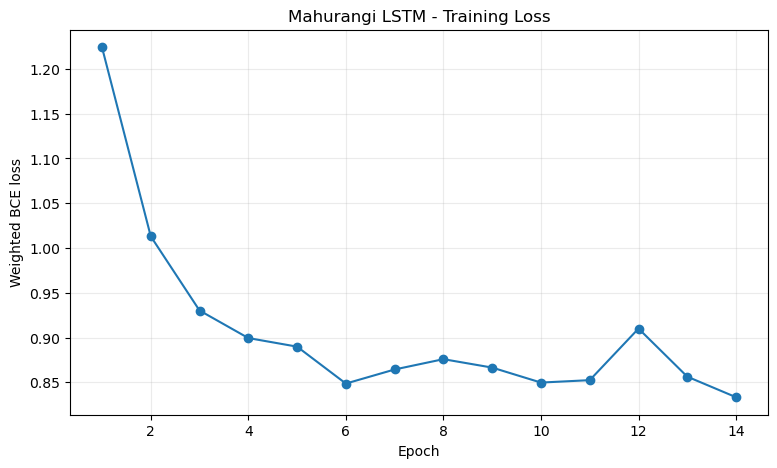

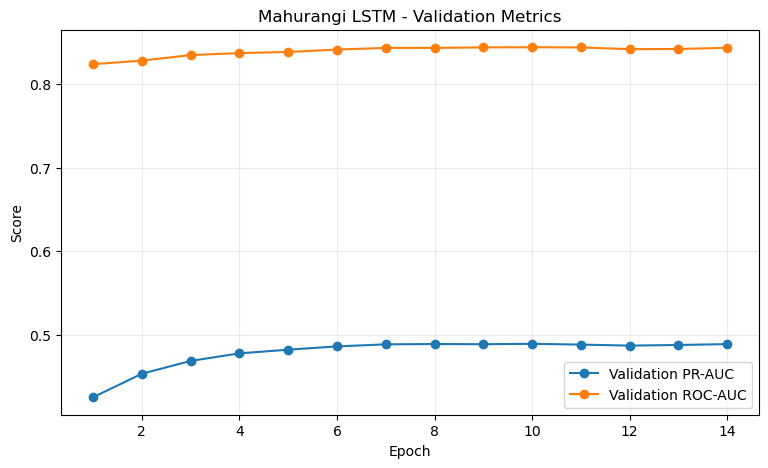

In [17]:
plt.figure(figsize=(9, 5))
plt.plot(history_df["epoch"], history_df["train_loss"], marker="o")
plt.xlabel("Epoch")
plt.ylabel("Weighted BCE loss")
plt.title("Mahurangi LSTM - Training Loss")
plt.grid(alpha=0.25)
plt.show()

plt.figure(figsize=(9, 5))
plt.plot(
    history_df["epoch"],
    history_df["validation_pr_auc"],
    marker="o",
    label="Validation PR-AUC",
)
plt.plot(
    history_df["epoch"],
    history_df["validation_roc_auc"],
    marker="o",
    label="Validation ROC-AUC",
)
plt.xlabel("Epoch")
plt.ylabel("Score")
plt.title("Mahurangi LSTM - Validation Metrics")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

## 13. Probability-Threshold Selection

The final threshold is selected using validation data only, by maximizing the **F2-score**.

In [18]:
model.eval()

with torch.no_grad():
    validation_probabilities = torch.sigmoid(
        model(torch.from_numpy(X_validation))
    ).cpu().numpy()

precision_curve, recall_curve, threshold_curve = precision_recall_curve(
    y_validation,
    validation_probabilities,
)

precision_for_threshold = precision_curve[:-1]
recall_for_threshold = recall_curve[:-1]

f2_curve = (
    5 * precision_for_threshold * recall_for_threshold
    / (
        4 * precision_for_threshold
        + recall_for_threshold
        + 1e-12
    )
)

best_position = np.argmax(f2_curve)
selected_probability_threshold = float(threshold_curve[best_position])

threshold_selection = pd.Series({
    "threshold": selected_probability_threshold,
    "precision": precision_for_threshold[best_position],
    "recall": recall_for_threshold[best_position],
    "f2_score": f2_curve[best_position],
})

display(threshold_selection.to_frame("Validation").round(4))

,Validation
threshold,0.6722
precision,0.3040
recall,0.5311
f2_score,0.4621


## 14. Validation metrics

In [19]:
validation_predictions = (
    validation_probabilities >= selected_probability_threshold
).astype(int)

v_tn, v_fp, v_fn, v_tp = confusion_matrix(
    y_validation,
    validation_predictions
).ravel()

validation_metrics = pd.Series({
    "threshold": selected_probability_threshold,
    "accuracy": accuracy_score(y_validation, validation_predictions),
    "precision": precision_score(
        y_validation, validation_predictions, zero_division=0
    ),
    "recall": recall_score(
        y_validation, validation_predictions, zero_division=0
    ),
    "f1_score": f1_score(
        y_validation, validation_predictions, zero_division=0
    ),
    "f2_score": fbeta_score(
        y_validation, validation_predictions, beta=2, zero_division=0
    ),
    "roc_auc": roc_auc_score(y_validation, validation_probabilities),
    "pr_auc": average_precision_score(
        y_validation, validation_probabilities
    ),
    "true_positives": v_tp,
    "false_negatives": v_fn,
    "false_positives": v_fp,
    "true_negatives": v_tn,
})

display(validation_metrics.to_frame("Validation").round(4))

,Validation
threshold,0.6722
accuracy,0.9079
precision,0.3040
recall,0.5311
f1_score,0.3867
f2_score,0.4621
roc_auc,0.8439
pr_auc,0.4895
true_positives,401.0000
false_negatives,354.0000


## 15. Final Test Evaluation

The test set is evaluated using the model and probability threshold already selected from training/validation. The model is not changed after observing test results.

In [20]:
X_test, y_test, test_timestamps, test_indices = create_sequences(
    model_data, scaled_features, LOOKBACK_HOURS, "test"
)

test_loader = DataLoader(
    TensorDataset(torch.from_numpy(X_test), torch.from_numpy(y_test)),
    batch_size=1024,
    shuffle=False,
)

model.eval()
test_probability_parts = []

with torch.no_grad():
    for X_batch, _ in test_loader:
        test_probability_parts.append(
            torch.sigmoid(model(X_batch)).cpu().numpy()
        )

test_probabilities = np.concatenate(test_probability_parts)

test_predictions_binary = (
    test_probabilities >= selected_probability_threshold
).astype(int)

tn, fp, fn, tp = confusion_matrix(
    y_test, test_predictions_binary
).ravel()

test_metrics = pd.Series({
    "selected_threshold": selected_probability_threshold,
    "accuracy": accuracy_score(y_test, test_predictions_binary),
    "precision": precision_score(
        y_test, test_predictions_binary, zero_division=0
    ),
    "recall": recall_score(
        y_test, test_predictions_binary, zero_division=0
    ),
    "f1_score": f1_score(
        y_test, test_predictions_binary, zero_division=0
    ),
    "f2_score": fbeta_score(
        y_test, test_predictions_binary, beta=2, zero_division=0
    ),
    "roc_auc": roc_auc_score(y_test, test_probabilities),
    "pr_auc": average_precision_score(y_test, test_probabilities),
    "true_positives": tp,
    "false_negatives": fn,
    "false_positives": fp,
    "true_negatives": tn,
})

print("X_test:", X_test.shape)
display(test_metrics.to_frame("Test").round(4))

print("\nClassification report:")
print(
    classification_report(
        y_test,
        test_predictions_binary,
        digits=4,
        zero_division=0,
    )
)

X_test: (12881, 48, 3)


,Test
selected_threshold,0.6722
accuracy,0.9297
precision,0.1968
recall,0.4587
f1_score,0.2754
f2_score,0.3623
roc_auc,0.8137
pr_auc,0.3662
true_positives,172.0000
false_negatives,203.0000



Classification report:
              precision    recall  f1-score   support

         0.0     0.9831    0.9439    0.9631     12506
         1.0     0.1968    0.4587    0.2754       375

    accuracy                         0.9297     12881
   macro avg     0.5899    0.7013    0.6193     12881
weighted avg     0.9602    0.9297    0.9431     12881



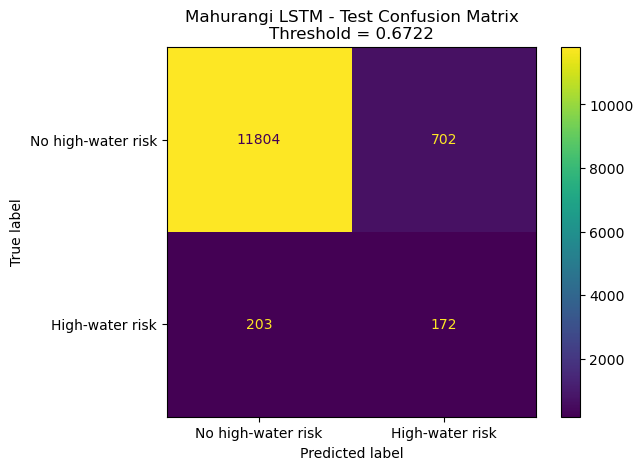

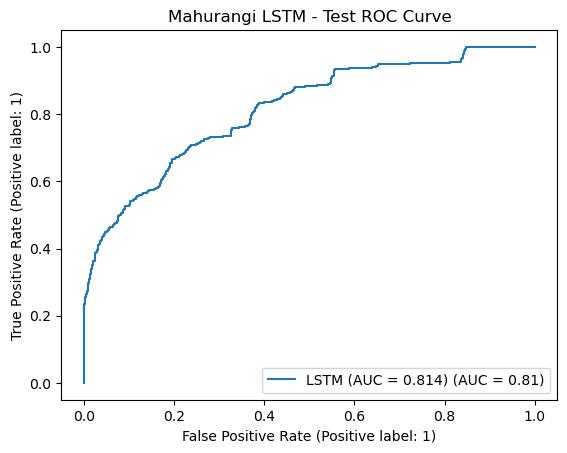

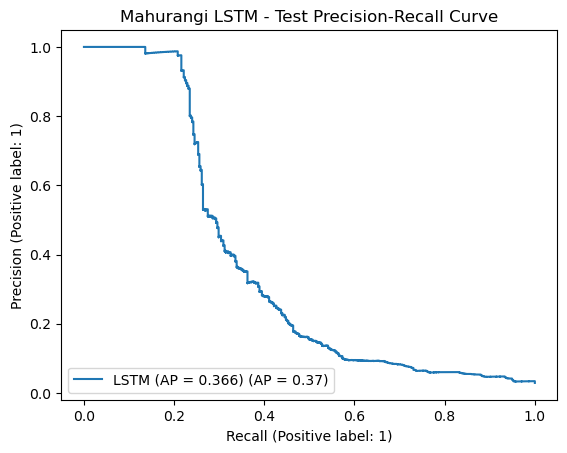

In [21]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions_binary,
    display_labels=["No high-water risk", "High-water risk"],
    values_format="d",
)
plt.title(
    "Mahurangi LSTM - Test Confusion Matrix\n"
    f"Threshold = {selected_probability_threshold:.4f}"
)
plt.show()

RocCurveDisplay.from_predictions(
    y_test,
    test_probabilities,
    name=f"LSTM (AUC = {roc_auc_score(y_test, test_probabilities):.3f})",
)
plt.title("Mahurangi LSTM - Test ROC Curve")
plt.show()

PrecisionRecallDisplay.from_predictions(
    y_test,
    test_probabilities,
    name=(
        "LSTM "
        f"(AP = {average_precision_score(y_test, test_probabilities):.3f})"
    ),
)
plt.title("Mahurangi LSTM - Test Precision-Recall Curve")
plt.show()

## 16. Reference Comparison with the Original Random Forest

Using the saved Mahurangi Random Forest test predictions, the baseline achieved approximately:

- Precision: 0.1616
- Recall: 0.4709
- F1: 0.2406
- F2: 0.341
- ROC-AUC: 0.794
- PR-AUC: 0.340


In [22]:
random_forest_reference = {
    "model": "Random Forest",
    "test_samples": 13696,
    "precision": 0.1616,
    "recall": 0.4709,
    "f1_score": 0.2406,
    "f2_score": 0.3410,
    "roc_auc": 0.7940,
    "pr_auc": 0.3400,
}

lstm_reference = {
    "model": "LSTM",
    "test_samples": len(y_test),
    "precision": test_metrics["precision"],
    "recall": test_metrics["recall"],
    "f1_score": test_metrics["f1_score"],
    "f2_score": test_metrics["f2_score"],
    "roc_auc": test_metrics["roc_auc"],
    "pr_auc": test_metrics["pr_auc"],
}

model_comparison = (
    pd.DataFrame([random_forest_reference, lstm_reference])
    .set_index("model")
)

display(model_comparison.round(4))

,test_samples,precision,recall,f1_score,f2_score,roc_auc,pr_auc
model,,,,,,,
Random Forest,13696,0.1616,0.4709,0.2406,0.3410,0.7940,0.3400
LSTM,12881,0.1968,0.4587,0.2754,0.3623,0.8137,0.3662


## 17. Hourly Predictions

In [23]:
test_predictions = pd.DataFrame({
    "timestamp": pd.to_datetime(test_timestamps),
    "actual_risk": y_test.astype(int),
    "risk_probability": test_probabilities,
    "predicted_risk": test_predictions_binary.astype(int),
})

display(test_predictions.head())
print("Prediction rows:", len(test_predictions))

,timestamp,actual_risk,risk_probability,predicted_risk
0,2024-05-08 10:00:00,0,0.054215,0
1,2024-05-08 11:00:00,0,0.052695,0
2,2024-05-08 12:00:00,0,0.050854,0
3,2024-05-08 13:00:00,0,0.049417,0
4,2024-05-08 14:00:00,0,0.048083,0


Prediction rows: 12881


## 18. Episode-Level Evaluation

Episodes are defined using all valid test-period target hours, not only the hours for which the LSTM could form a complete sequence.

An episode is considered detected if at least one positive LSTM prediction overlaps that model-defined high-water-risk episode. This is a diagnostic measure and does not represent independently verified historical flood-event detection.

In [24]:
full_test_target = (
    model_data.loc[
        model_data["data_period"].eq("test")
        & model_data["flood_next_24h"].notna(),
        ["timestamp", "flood_next_24h"],
    ]
    .rename(columns={"flood_next_24h": "actual_risk"})
    .copy()
)

full_test_target["actual_risk"] = (
    full_test_target["actual_risk"].astype(int)
)

event_frame = (
    full_test_target
    .merge(
        test_predictions[
            ["timestamp", "risk_probability", "predicted_risk"]
        ],
        on="timestamp",
        how="left",
    )
    .sort_values("timestamp")
    .reset_index(drop=True)
)

event_frame["predicted_risk_for_detection"] = (
    event_frame["predicted_risk"].fillna(0).astype(int)
)

actual_positive = event_frame["actual_risk"].eq(1)
timestamp_gap = (
    event_frame["timestamp"].diff().ne(pd.Timedelta(hours=1))
)

new_event = (
    actual_positive
    & (
        ~actual_positive.shift(fill_value=False)
        | timestamp_gap
    )
)

event_frame["event_id"] = new_event.cumsum().where(actual_positive)

event_level_results = (
    event_frame.loc[actual_positive]
    .groupby("event_id")
    .agg(
        event_start=("timestamp", "min"),
        event_end=("timestamp", "max"),
        event_duration_hours=("timestamp", "size"),
        detected_hours=("predicted_risk_for_detection", "sum"),
        maximum_risk_score=("risk_probability", "max"),
        mean_risk_score=("risk_probability", "mean"),
    )
    .reset_index()
)

event_level_results["event_detected"] = (
    event_level_results["detected_hours"] > 0
)

event_level_results["hourly_detection_percentage"] = (
    100
    * event_level_results["detected_hours"]
    / event_level_results["event_duration_hours"]
)

display(event_level_results)

print(
    "Event detection rate:",
    round(event_level_results["event_detected"].mean() * 100, 2),
    "%"
)

,event_id,event_start,event_end,event_duration_hours,detected_hours,maximum_risk_score,mean_risk_score,event_detected,hourly_detection_percentage
0,1.0,2024-05-20 00:00:00,2024-05-21 01:00:00,26,6,0.990475,0.282506,True,23.076923
1,2.0,2024-06-13 11:00:00,2024-06-14 13:00:00,27,0,NaN,NaN,False,0.000000
2,3.0,2024-06-15 22:00:00,2024-06-17 02:00:00,29,8,0.993603,0.669216,True,27.586207
3,4.0,2024-07-14 16:00:00,2024-07-15 20:00:00,29,16,0.993619,0.711709,True,55.172414
4,5.0,2024-07-19 02:00:00,2024-07-20 05:00:00,28,10,0.982089,0.680669,True,35.714286
5,6.0,2024-08-29 01:00:00,2024-08-30 00:00:00,24,5,0.985995,0.568709,True,20.833333
6,7.0,2025-04-18 00:00:00,2025-04-19 06:00:00,31,16,0.994187,0.738523,True,51.612903
7,8.0,2025-06-26 09:00:00,2025-06-27 14:00:00,30,13,0.993561,0.681715,True,43.333333
8,9.0,2025-07-02 15:00:00,2025-07-03 21:00:00,31,19,0.990424,0.756154,True,61.290323
9,10.0,2025-07-10 14:00:00,2025-07-12 00:00:00,35,35,0.994382,0.874789,True,100.000000


Event detection rate: 92.31 %


In [25]:
alert_frame = (
    test_predictions
    .sort_values("timestamp")
    .reset_index(drop=True)
    .copy()
)

predicted_positive = alert_frame["predicted_risk"].eq(1)

alert_gap = (
    alert_frame["timestamp"].diff().ne(pd.Timedelta(hours=1))
)

new_alert = (
    predicted_positive
    & (
        ~predicted_positive.shift(fill_value=False)
        | alert_gap
    )
)

alert_frame["alert_id"] = (
    new_alert.cumsum().where(predicted_positive)
)

alert_episode_results = (
    alert_frame.loc[predicted_positive]
    .groupby("alert_id")
    .agg(
        alert_start=("timestamp", "min"),
        alert_end=("timestamp", "max"),
        alert_duration_hours=("timestamp", "size"),
        actual_risk_hours=("actual_risk", "sum"),
        maximum_risk_score=("risk_probability", "max"),
        mean_risk_score=("risk_probability", "mean"),
    )
    .reset_index()
)

alert_episode_results["associated_with_risk"] = (
    alert_episode_results["actual_risk_hours"] > 0
)

display(alert_episode_results.head(20))

print("Alert episodes:", len(alert_episode_results))

if len(alert_episode_results) > 0:
    print(
        "Alerts associated with risk:",
        round(
            alert_episode_results["associated_with_risk"].mean() * 100,
            2
        ),
        "%"
    )

,alert_id,alert_start,alert_end,alert_duration_hours,actual_risk_hours,maximum_risk_score,mean_risk_score,associated_with_risk
0,1.0,2024-05-15 06:00:00,2024-05-15 07:00:00,2,0,0.859212,0.847778,False
1,2.0,2024-05-15 13:00:00,2024-05-15 14:00:00,2,0,0.881979,0.790133,False
2,3.0,2024-05-20 20:00:00,2024-05-21 05:00:00,10,6,0.990475,0.907520,True
3,4.0,2024-05-24 22:00:00,2024-05-24 22:00:00,1,0,0.769248,0.769248,False
4,5.0,2024-05-25 07:00:00,2024-05-25 07:00:00,1,0,0.703661,0.703661,False
5,6.0,2024-05-28 20:00:00,2024-05-29 02:00:00,7,0,0.923757,0.831523,False
6,7.0,2024-05-29 11:00:00,2024-05-29 15:00:00,5,0,0.919344,0.783014,False
7,8.0,2024-05-29 17:00:00,2024-05-29 22:00:00,6,0,0.901192,0.762393,False
8,9.0,2024-06-16 19:00:00,2024-06-17 07:00:00,13,8,0.993603,0.920799,True
9,10.0,2024-06-21 03:00:00,2024-06-21 05:00:00,3,0,0.805916,0.752304,False


Alert episodes: 183
Alerts associated with risk: 8.74 %


## 19. Save the Model and Results

In [26]:
output_dir = Path("outputs") / "mahurangi_lstm"
output_dir.mkdir(parents=True, exist_ok=True)

torch.save(
    {
        "model_state_dict": model.state_dict(),
        "lookback_hours": LOOKBACK_HOURS,
        "feature_columns": feature_columns,
        "hidden_size": 32,
        "dense_size": 16,
        "selected_probability_threshold": selected_probability_threshold,
        "high_water_threshold_m": float(high_water_threshold),
        "seed": SEED,
    },
    output_dir / "mahurangi_lstm_model.pt",
)

joblib.dump(
    scaler,
    output_dir / "mahurangi_lstm_scaler.pkl"
)

test_predictions.to_csv(
    output_dir / "mahurangi_lstm_test_predictions.csv",
    index=False,
)

event_level_results.to_csv(
    output_dir / "mahurangi_lstm_event_level_results.csv",
    index=False,
)

alert_episode_results.to_csv(
    output_dir / "mahurangi_lstm_alert_episode_results.csv",
    index=False,
)

validation_metrics.to_frame("value").to_csv(
    output_dir / "mahurangi_lstm_validation_metrics.csv"
)

test_metrics.to_frame("value").to_csv(
    output_dir / "mahurangi_lstm_test_metrics.csv"
)

history_df.to_csv(
    output_dir / "mahurangi_lstm_training_history.csv",
    index=False,
)

model_comparison.to_csv(
    output_dir / "mahurangi_lstm_model_comparison.csv"
)

print("Saved to:", output_dir.resolve())
for file in sorted(output_dir.iterdir()):
    print("-", file.name)

Saved to: C:\Users\lauso\AA Capstone Project\outputs\mahurangi_lstm
- mahurangi_lstm_alert_episode_results.csv
- mahurangi_lstm_event_level_results.csv
- mahurangi_lstm_model.pt
- mahurangi_lstm_model_comparison.csv
- mahurangi_lstm_scaler.pkl
- mahurangi_lstm_test_metrics.csv
- mahurangi_lstm_test_predictions.csv
- mahurangi_lstm_training_history.csv
- mahurangi_lstm_validation_metrics.csv
